In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("ealaxi/paysim1")

print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, "PS_20174392719_1491204439457_log.csv"))

Using Colab cache for faster access to the 'paysim1' dataset.
Path to dataset files: /kaggle/input/paysim1


In [ ]:
df.sample(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
3795640,281,CASH_OUT,129771.03,C605533815,0.00,0.00,C1623172019,141426.95,271197.98,0,0
3155117,237,PAYMENT,4275.99,C314520043,16643.00,12367.01,M131407403,0.00,0.00,0,0
2895467,228,PAYMENT,31400.65,C765118046,0.00,0.00,M203647292,0.00,0.00,0,0
1732637,161,PAYMENT,8513.12,C1329006042,14352.00,5838.88,M1092809552,0.00,0.00,0,0
558764,22,PAYMENT,18095.35,C6480688,440.00,0.00,M19663406,0.00,0.00,0,0
3843709,282,CASH_OUT,96808.85,C118432845,32284.00,0.00,C1430710604,1076755.72,1173564.57,0,0
5056086,354,PAYMENT,1005.69,C1651231643,78363.92,77358.23,M1752003500,0.00,0.00,0,0
140319,11,TRANSFER,34494.81,C1278392538,667579.46,633084.65,C1938126565,51088.00,0.00,0,0
745372,38,CASH_OUT,353812.86,C1136638154,0.00,0.00,C1191652178,627796.03,981608.89,0,0
256065,14,CASH_OUT,161157.95,C1604004008,39935.00,0.00,C672662411,394294.22,588936.18,0,0


In [ ]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [ ]:
df.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [ ]:
df.shape

(6362620, 11)

In [ ]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [ ]:
df['isFraud'].value_counts()

,count
isFraud,
0,6354407
1,8213


In [ ]:
df['isFraud'].value_counts(normalize=True) * 100

,proportion
isFraud,
0,99.870918
1,0.129082


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['type'].value_counts()

,count
type,
CASH_OUT,2237500
PAYMENT,2151495
CASH_IN,1399284
TRANSFER,532909
DEBIT,41432


In [ ]:
df['type'].value_counts(normalize=True) * 100

,proportion
type,
CASH_OUT,35.166331
PAYMENT,33.814608
CASH_IN,21.992261
TRANSFER,8.375622
DEBIT,0.651178


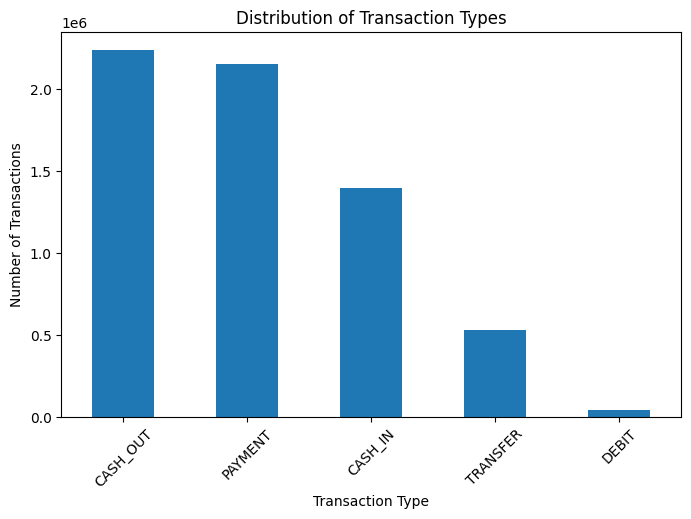

In [ ]:
df['type'].value_counts().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Distribution of Transaction Types')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)

plt.show()

In [ ]:
df.groupby('type')['isFraud'].sum()

,isFraud
type,
CASH_IN,0
CASH_OUT,4116
DEBIT,0
PAYMENT,0
TRANSFER,4097


In [ ]:
df.groupby('type')['isFraud'].mean() * 100

,isFraud
type,
CASH_IN,0.000000
CASH_OUT,0.183955
DEBIT,0.000000
PAYMENT,0.000000
TRANSFER,0.768799


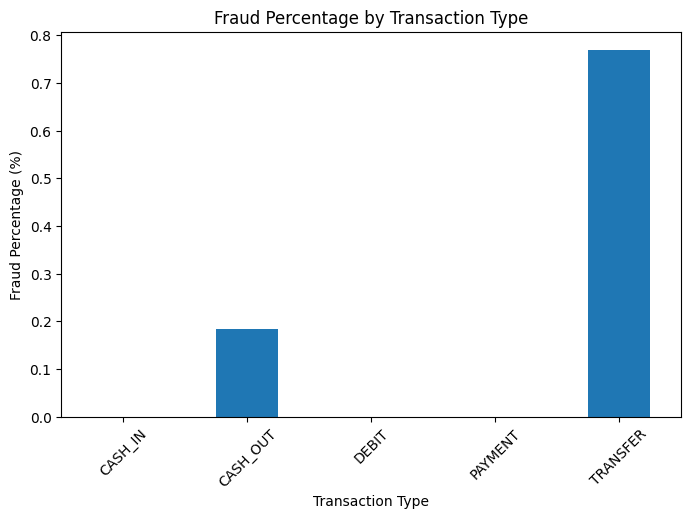

In [ ]:
fraud_percentage = df.groupby('type')['isFraud'].mean() * 100

fraud_percentage.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Fraud Percentage by Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('Fraud Percentage (%)')
plt.xticks(rotation=45)

plt.show()

In [ ]:
df['amount'].describe()

,amount
count,6.362620e+06
mean,1.798619e+05
std,6.038582e+05
min,0.000000e+00
25%,1.338957e+04
50%,7.487194e+04
75%,2.087215e+05
max,9.244552e+07


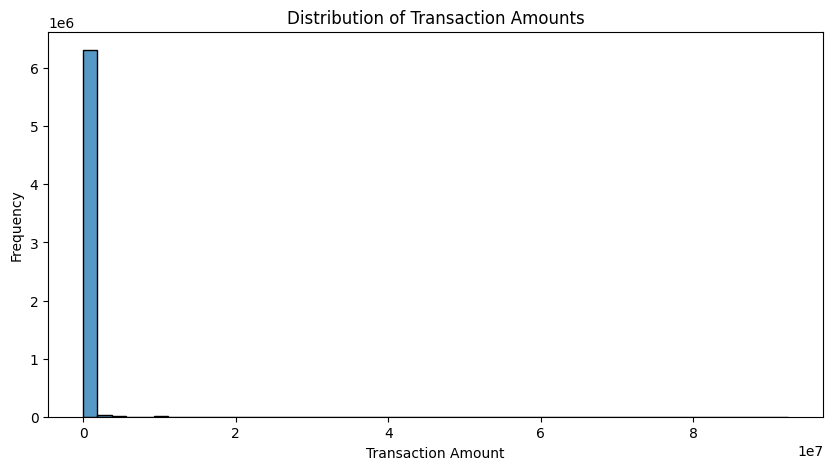

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(df['amount'], bins=50)

plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

plt.show()


In [ ]:

df.groupby('isFraud')['amount'].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


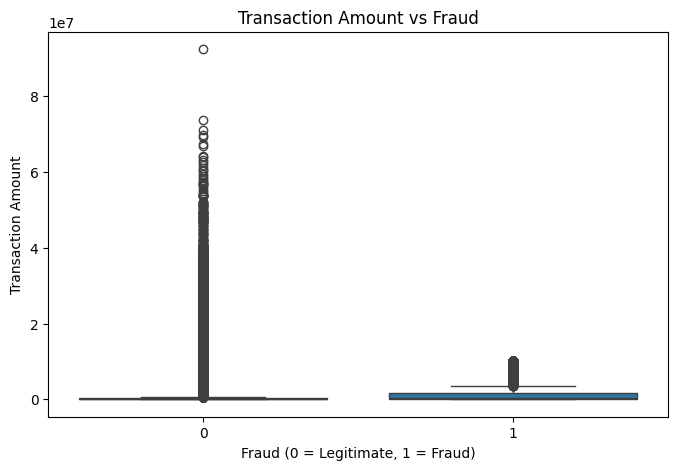

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='isFraud',
    y='amount'
)

plt.title('Transaction Amount vs Fraud')
plt.xlabel('Fraud (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Transaction Amount')

plt.show()

In [ ]:
df.groupby('type')['amount'].mean().sort_values(ascending=False)

,amount
type,
TRANSFER,910647.009645
CASH_OUT,176273.964346
CASH_IN,168920.242004
PAYMENT,13057.604660
DEBIT,5483.665314


In [ ]:
df.groupby('type').agg(
    total_transactions=('isFraud', 'count'),
    fraud_transactions=('isFraud', 'sum'),
    average_amount=('amount', 'mean'),
    fraud_rate=('isFraud', 'mean')
)

,total_transactions,fraud_transactions,average_amount,fraud_rate
type,,,,
CASH_IN,1399284,0,168920.242004,0.000000
CASH_OUT,2237500,4116,176273.964346,0.001840
DEBIT,41432,0,5483.665314,0.000000
PAYMENT,2151495,0,13057.604660,0.000000
TRANSFER,532909,4097,910647.009645,0.007688


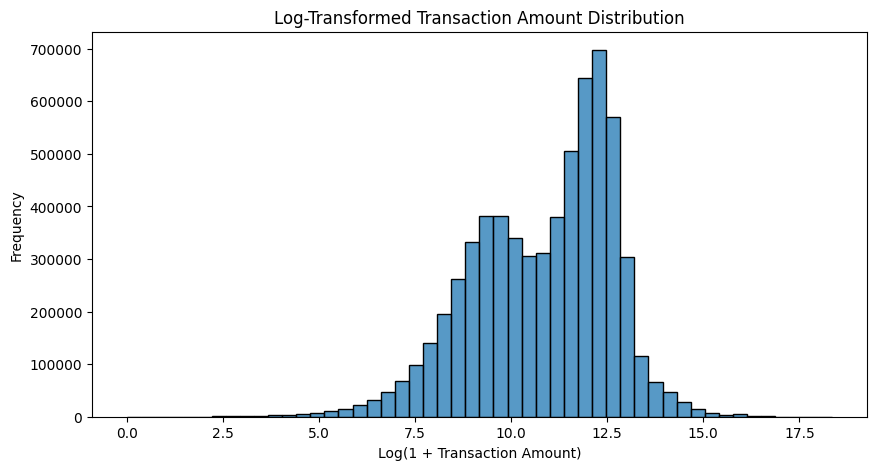

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(df['amount']),
    bins=50
)

plt.title('Log-Transformed Transaction Amount Distribution')
plt.xlabel('Log(1 + Transaction Amount)')
plt.ylabel('Frequency')

plt.show()

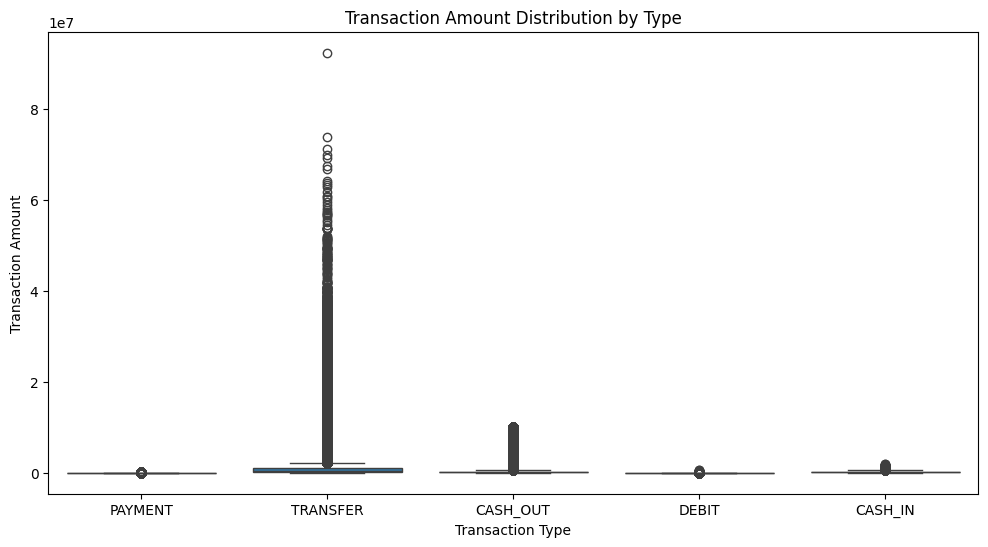

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='type',
    y='amount'
)

plt.title('Transaction Amount Distribution by Type')
plt.xlabel('Transaction Type')
plt.ylabel('Transaction Amount')

plt.show()

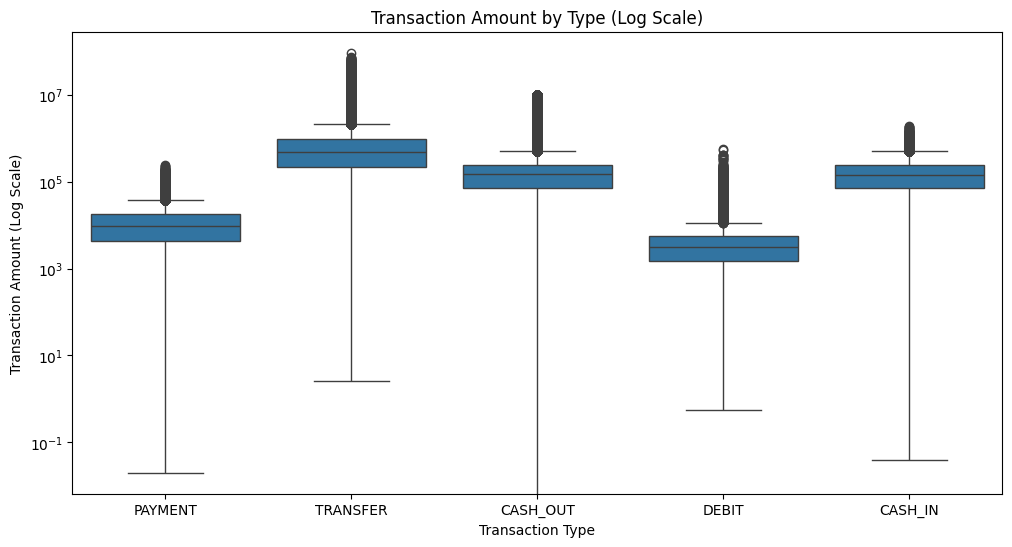

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='type',
    y='amount'
)

plt.yscale('log')

plt.title('Transaction Amount by Type (Log Scale)')
plt.xlabel('Transaction Type')
plt.ylabel('Transaction Amount (Log Scale)')

plt.show()

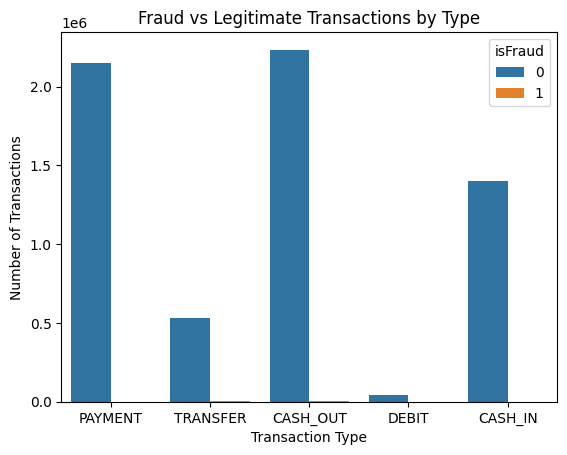

In [ ]:
sns.countplot(data=df, x='type', hue='isFraud')

plt.title('Fraud vs Legitimate Transactions by Type')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')

plt.show()

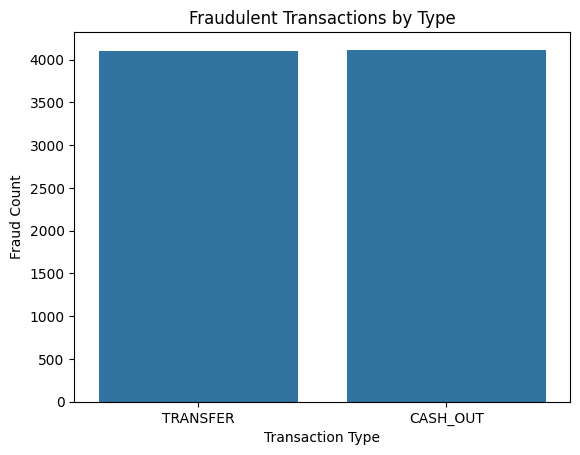

In [ ]:
fraud_data = df[df['isFraud'] == 1]

sns.countplot(data=fraud_data, x='type')

plt.title('Fraudulent Transactions by Type')
plt.xlabel('Transaction Type')
plt.ylabel('Fraud Count')

plt.show()

In [ ]:
df.sample()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
607581,34,TRANSFER,83686.85,C964144866,0.0,0.0,C745052250,279713.97,503796.13,0,0


In [ ]:
df['step'].describe()

,step
count,6.362620e+06
mean,2.433972e+02
std,1.423320e+02
min,1.000000e+00
25%,1.560000e+02
50%,2.390000e+02
75%,3.350000e+02
max,7.430000e+02


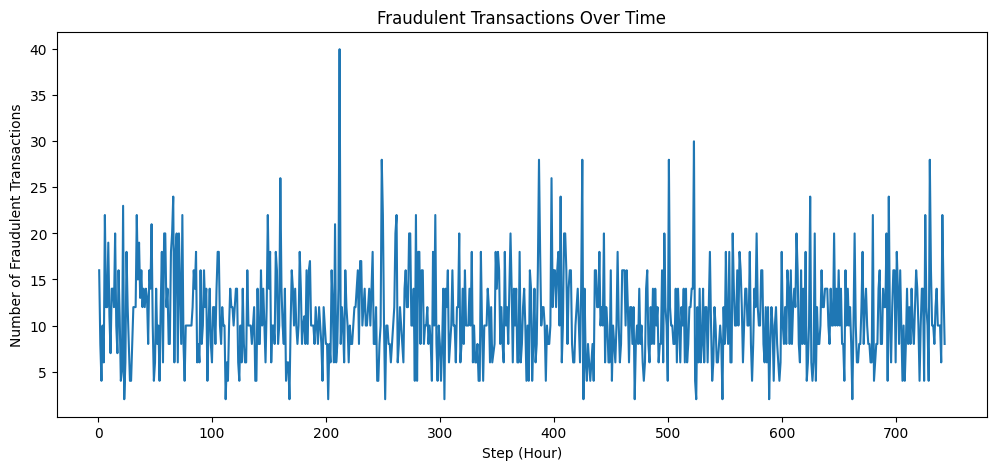

In [ ]:
fraud_by_step = df[df['isFraud'] == 1].groupby('step')['isFraud'].sum()

fraud_by_step.plot(figsize=(12, 5))

plt.title('Fraudulent Transactions Over Time')
plt.xlabel('Step (Hour)')
plt.ylabel('Number of Fraudulent Transactions')

plt.show()

In [ ]:
df.groupby('isFraud')['step'].mean()

,step
isFraud,
0,243.235663
1,368.413856


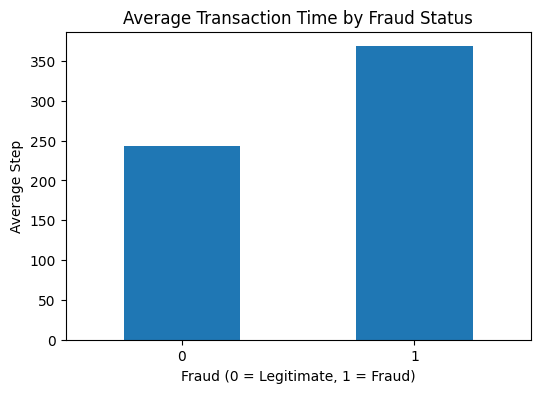

In [ ]:
df.groupby('isFraud')['step'].mean().plot(
    kind='bar',
    figsize=(6, 4)
)

plt.title('Average Transaction Time by Fraud Status')
plt.xlabel('Fraud (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Average Step')

plt.xticks(rotation=0)
plt.show()

In [ ]:
df['oldbalanceOrg'].describe()

,oldbalanceOrg
count,6.362620e+06
mean,8.338831e+05
std,2.888243e+06
min,0.000000e+00
25%,0.000000e+00
50%,1.420800e+04
75%,1.073152e+05
max,5.958504e+07


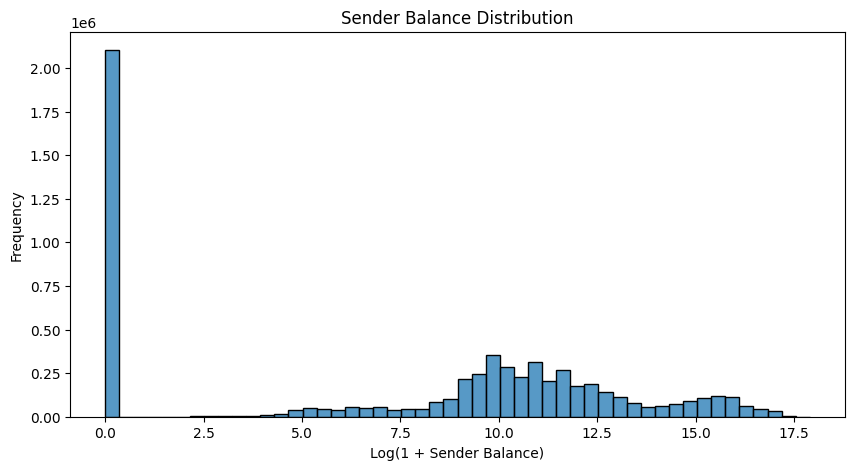

In [ ]:
plt.figure(figsize = (10,5))
sns.histplot(np.log1p(df['oldbalanceOrg']) , bins = 50)

plt.title('Sender Balance Distribution')
plt.xlabel('Log(1 + Sender Balance)')
plt.ylabel('Frequency')
plt.show()

In [ ]:
df['newbalanceOrig'].describe()

,newbalanceOrig
count,6.362620e+06
mean,8.551137e+05
std,2.924049e+06
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,1.442584e+05
max,4.958504e+07


In [ ]:
df[['oldbalanceOrg', 'newbalanceOrig']].mean()

,0
oldbalanceOrg,833883.104074
newbalanceOrig,855113.668579


In [ ]:
df.groupby('type')[['oldbalanceOrg', 'newbalanceOrig']].mean()

,oldbalanceOrg,newbalanceOrig
type,,
CASH_IN,3.590464e+06,3.759379e+06
CASH_OUT,4.602380e+04,1.747419e+04
DEBIT,6.864734e+04,6.516165e+04
PAYMENT,6.821683e+04,6.183789e+04
TRANSFER,5.444185e+04,1.028816e+04


In [ ]:
df['oldbalanceDest'].describe()

,oldbalanceDest
count,6.362620e+06
mean,1.100702e+06
std,3.399180e+06
min,0.000000e+00
25%,0.000000e+00
50%,1.327057e+05
75%,9.430367e+05
max,3.560159e+08


In [ ]:
df['newbalanceDest'].describe()


,newbalanceDest
count,6.362620e+06
mean,1.224996e+06
std,3.674129e+06
min,0.000000e+00
25%,0.000000e+00
50%,2.146614e+05
75%,1.111909e+06
max,3.561793e+08


In [ ]:
df['newbalanceDest'].max()

356179278.92

In [ ]:
df[['oldbalanceDest', 'newbalanceDest']].mean()

,0
oldbalanceDest,1.100702e+06
newbalanceDest,1.224996e+06


In [ ]:
df['sender_balance_change'] = df['newbalanceOrig'] - df['oldbalanceOrg']

df['receiver_balance_change'] = df['newbalanceDest'] - df['oldbalanceDest']

In [ ]:
df[['sender_balance_change', 'receiver_balance_change']].describe()

,sender_balance_change,receiver_balance_change
count,6.362620e+06,6.362620e+06
mean,2.123056e+04,1.242947e+05
std,1.466433e+05,8.129391e+05
min,-1.000000e+07,-1.306083e+07
25%,-1.015044e+04,0.000000e+00
50%,0.000000e+00,0.000000e+00
75%,0.000000e+00,1.491054e+05
max,1.915268e+06,1.056878e+08


In [ ]:
df.groupby('isFraud')[['sender_balance_change', 'receiver_balance_change']].mean()


,sender_balance_change,receiver_balance_change
isFraud,,
0,2.314152e+04,123504.809994
1,-1.457275e+06,735457.998071


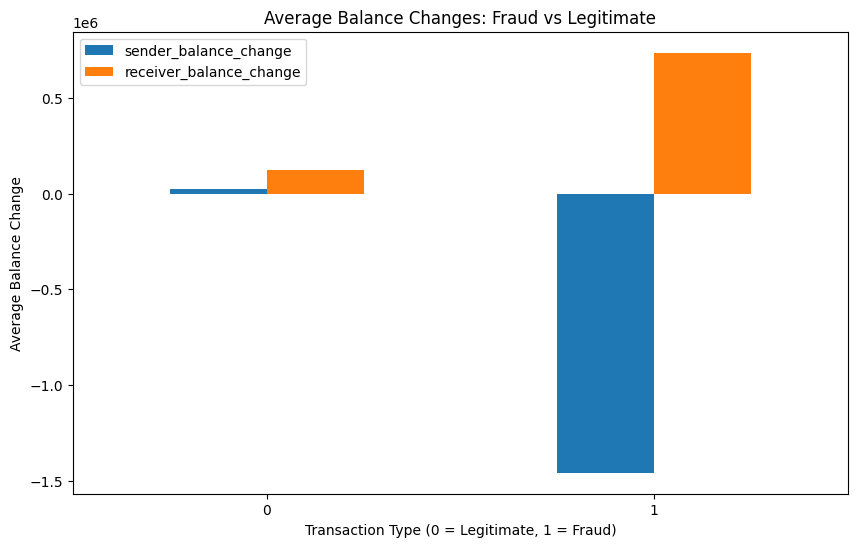

In [ ]:


balance_change = df.groupby('isFraud')[
    ['sender_balance_change', 'receiver_balance_change']
].mean()

balance_change.plot(kind='bar', figsize=(10, 6))

plt.title('Average Balance Changes: Fraud vs Legitimate')
plt.xlabel('Transaction Type (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Average Balance Change')
plt.xticks(rotation=0)
plt.show()

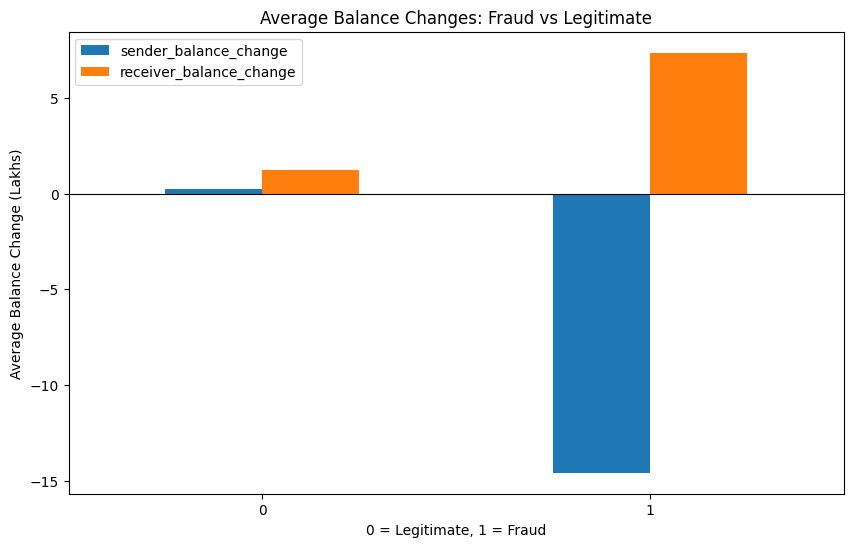

In [ ]:
balance_change = df.groupby('isFraud')[
    ['sender_balance_change', 'receiver_balance_change']
].mean()

balance_change = balance_change / 100000

balance_change.plot(kind='bar', figsize=(10, 6))

plt.title('Average Balance Changes: Fraud vs Legitimate')
plt.xlabel('0 = Legitimate, 1 = Fraud')
plt.ylabel('Average Balance Change (Lakhs)')
plt.xticks(rotation=0)
plt.axhline(0, color='black', linewidth=0.8)
plt.show()

In [ ]:
df[['nameOrig', 'nameDest']].head()

,nameOrig,nameDest
0,C1231006815,M1979787155
1,C1666544295,M2044282225
2,C1305486145,C553264065
3,C840083671,C38997010
4,C2048537720,M1230701703


In [ ]:
print("Unique sender accounts:", df['nameOrig'].nunique())

print("Unique receiver accounts:", df['nameDest'].nunique())

Unique sender accounts: 6353307
Unique receiver accounts: 2722362


In [ ]:
df['nameDest'].value_counts().head(10)

,count
nameDest,
C1286084959,113
C985934102,109
C665576141,105
C2083562754,102
C248609774,101
C1590550415,101
C1789550256,99
C451111351,99
C1360767589,98


In [ ]:
top_receivers = df['nameDest'].value_counts().head(10).index

df[df['nameDest'].isin(top_receivers)].groupby('nameDest')['isFraud'].sum()


,isFraud
nameDest,
C1023714065,0
C1286084959,0
C1360767589,0
C1590550415,0
C1789550256,0
C2083562754,0
C248609774,0
C451111351,0
C665576141,0


In [ ]:
df['nameDest'].str[0].value_counts()

,count
nameDest,
C,4211125
M,2151495


In [ ]:
df.groupby(df['nameDest'].str[0])['isFraud'].agg(
    total_transactions='count',
    fraud_transactions='sum',
    fraud_rate='mean'
)


,total_transactions,fraud_transactions,fraud_rate
nameDest,,,
C,4211125,8213,0.00195
M,2151495,0,0.00000


In [ ]:
df['isFlaggedFraud'].value_counts()

,count
isFlaggedFraud,
0,6362604
1,16


In [ ]:
df[df['isFlaggedFraud'] == 1][
    ['type', 'amount', 'isFraud', 'isFlaggedFraud']
]

,type,amount,isFraud,isFlaggedFraud
2736446,TRANSFER,4953893.08,1,1
3247297,TRANSFER,1343002.08,1,1
3760288,TRANSFER,536624.41,1,1
5563713,TRANSFER,4892193.09,1,1
5996407,TRANSFER,10000000.00,1,1
5996409,TRANSFER,9585040.37,1,1
6168499,TRANSFER,3576297.10,1,1
6205439,TRANSFER,353874.22,1,1
6266413,TRANSFER,2542664.27,1,1
6281482,TRANSFER,10000000.00,1,1


In [ ]:
df['expected_newbalanceOrig'] = (
    df['oldbalanceOrg'] - df['amount']
)

df['sender_balance_error'] = (
    df['newbalanceOrig'] - df['expected_newbalanceOrig']
)

In [ ]:
df['sender_balance_error'].describe()

,sender_balance_error
count,6.362620e+06
mean,2.010925e+05
std,6.066505e+05
min,-1.000000e-02
25%,2.954230e+03
50%,6.867726e+04
75%,2.496411e+05
max,9.244552e+07


In [ ]:
df.groupby('type')['sender_balance_error'].mean()

,sender_balance_error
type,
CASH_IN,337835.445783
CASH_OUT,147724.352289
DEBIT,1997.980151
PAYMENT,6678.667998
TRANSFER,866493.314624


In [ ]:
df.groupby('isFraud')['sender_balance_error'].mean()

,sender_balance_error
isFraud,
0,201338.558109
1,10692.325265


In [ ]:
df[df['type'].isin(['TRANSFER', 'CASH_OUT'])].groupby(
    ['type', 'isFraud']
)['sender_balance_error'].mean()

type      isFraud
CASH_OUT  0          147994.192774
          1            1306.125231
TRANSFER  0          873050.622427
          1           20122.054174
Name: sender_balance_error, dtype: float64

In [ ]:
fraud_data = df[df['isFraud'] == 1]

fraud_data[['type', 'amount', 'sender_balance_change']].head(10)

,type,amount,sender_balance_change
2,TRANSFER,181.00,-181.00
3,CASH_OUT,181.00,-181.00
251,TRANSFER,2806.00,-2806.00
252,CASH_OUT,2806.00,-2806.00
680,TRANSFER,20128.00,-20128.00
681,CASH_OUT,20128.00,-20128.00
724,CASH_OUT,416001.33,0.00
969,TRANSFER,1277212.77,-1277212.77
970,CASH_OUT,1277212.77,-1277212.77
1115,TRANSFER,35063.63,-35063.63


In [ ]:
fraud_data = df[df['isFraud'] == 1]

(fraud_data['sender_balance_change'] == 0).sum()

np.int64(57)

In [ ]:
(fraud_data['sender_balance_change'] == 0).mean() * 100

np.float64(0.6940216729575064)

In [ ]:
(fraud_data['receiver_balance_change'] == 0).sum()

np.int64(4086)

In [ ]:
(fraud_data['receiver_balance_change'] == 0).mean() * 100

np.float64(49.750395714111775)

In [ ]:
df.drop(
    columns=[
        'sender_balance_change',
        'receiver_balance_change',
        'expected_newbalanceOrig',
        'sender_balance_error'
    ],
    inplace=True
)

In [ ]:
df.shape

(6362620, 11)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [ ]:
df.nunique()

,0
step,743
type,5
amount,5316900
nameOrig,6353307
oldbalanceOrg,1845844
newbalanceOrig,2682586
nameDest,2722362
oldbalanceDest,3614697
newbalanceDest,3555499
isFraud,2


In [ ]:
df['type'].unique()

array(['PAYMENT', 'TRANSFER', 'CASH_OUT', 'DEBIT', 'CASH_IN'],
      dtype=object)

In [ ]:
sample = pd.DataFrame({
    'type': ['PAYMENT', 'TRANSFER', 'CASH_OUT', 'CASH_IN']
})

pd.get_dummies(sample['type'])

,CASH_IN,CASH_OUT,PAYMENT,TRANSFER
0,False,False,True,False
1,False,False,False,True
2,False,True,False,False
3,True,False,False,False


In [ ]:
df_encoded = pd.get_dummies(
    df,
  columns=['type'],
  dtype=int)

In [ ]:
df_encoded.head()

,step,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,1,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,0,0,0,1,0
1,1,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,0,0,0,1,0
2,1,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,0,0,0,0,1
3,1,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,0,1,0,0,0
4,1,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,0,0,0,1,0


In [ ]:
df_encoded.columns

Index(['step', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT',
       'type_PAYMENT', 'type_TRANSFER'],
      dtype='object')

In [ ]:
df_encoded.drop(columns=['nameOrig','nameDest','isFlaggedFraud'],inplace=True)

In [ ]:
df_encoded.columns

Index(['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest',
       'newbalanceDest', 'isFraud', 'type_CASH_IN', 'type_CASH_OUT',
       'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER'],
      dtype='object')

In [ ]:
df_encoded.shape

(6362620, 12)

In [ ]:
X = df_encoded.drop(columns=['isFraud'])
y = df_encoded['isFraud']

In [ ]:
print(X.shape)
print(y.shape)

(6362620, 11)
(6362620,)


In [ ]:
y.value_counts()

,count
isFraud,
0,6354407
1,8213


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5090096, 11)
X_test: (1272524, 11)
y_train: (5090096,)
y_test: (1272524,)


In [ ]:
print(y_train.value_counts(normalize=True)*100)
print(y_test.value_counts(normalize=True)*100)

isFraud
0    99.870926
1     0.129074
Name: proportion, dtype: float64
isFraud
0    99.870887
1     0.129113
Name: proportion, dtype: float64


In [ ]:
X_train.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
count,5.090096e+06,5.090096e+06,5.090096e+06,5.090096e+06,5.090096e+06,5.090096e+06,5.090096e+06,5.090096e+06,5.090096e+06,5.090096e+06,5.090096e+06
mean,2.433626e+02,1.799096e+05,8.337449e+05,8.549461e+05,1.100383e+06,1.224793e+06,2.198438e-01,3.517236e-01,6.512058e-03,3.381535e-01,8.376699e-02
std,1.423198e+02,6.024578e+05,2.887601e+06,2.923387e+06,3.403515e+06,3.676909e+06,4.141407e-01,4.775083e-01,8.043415e-02,4.730811e-01,2.770381e-01
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.550000e+02,1.339099e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.484103e+04,1.421200e+04,0.000000e+00,1.328011e+05,2.150132e+05,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.086834e+05,1.073380e+05,1.441687e+05,9.431530e+05,1.112537e+06,0.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [ ]:
num_cols = [
    'step',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols)
    ],
    remainder='passthrough'
)

In [ ]:
preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('num', StandardScaler(),
                                 ['step', 'amount', 'oldbalanceOrg',
                                  'newbalanceOrig', 'oldbalanceDest',
                                  'newbalanceDest'])])

In [ ]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression())
])

In [ ]:
pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  ['step', 'amount',
                                                   'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest'])])),
                ('model', LogisticRegression())])

In [ ]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

In [ ]:
pipeline.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  ['step', 'amount',
                                                   'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [ ]:
y_pred = pipeline.predict(X_test)

In [ ]:
y_pred.shape

(1272524,)

In [ ]:
np.unique(y_pred, return_counts=True)

(array([0, 1]), array([1206199,   66325]))

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

cm

array([[1206133,   64748],
       [     66,    1577]])

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1270881
           1       0.02      0.96      0.05      1643

    accuracy                           0.95   1272524
   macro avg       0.51      0.95      0.51   1272524
weighted avg       1.00      0.95      0.97   1272524



In [ ]:
classification_report(y_test, y_pred)

'              precision    recall  f1-score   support\n\n           0       1.00      0.95      0.97   1270881\n           1       0.02      0.96      0.05      1643\n\n    accuracy                           0.95   1272524\n   macro avg       0.51      0.95      0.51   1272524\nweighted avg       1.00      0.95      0.97   1272524\n'

In [ ]:
y_proba = pipeline.predict_proba(X_test)

In [ ]:
y_proba[:5]

array([[9.99835174e-01, 1.64825949e-04],
       [1.00000000e+00, 6.16110016e-59],
       [1.00000000e+00, 4.84170967e-69],
       [9.32898170e-01, 6.71018301e-02],
       [7.87291965e-01, 2.12708035e-01]])

In [ ]:
y_pred_08 = (y_proba[:, 1] >= 0.8).astype(int)

In [ ]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, y_pred_08)

array([[1252394,   18487],
       [    256,    1387]])

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_08))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99   1270881
           1       0.07      0.84      0.13      1643

    accuracy                           0.99   1272524
   macro avg       0.53      0.91      0.56   1272524
weighted avg       1.00      0.99      0.99   1272524



In [ ]:
y_pred_06 = (y_proba[:, 1] >= 0.6).astype(int)

In [ ]:
print(classification_report(y_test, y_pred_06))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98   1270881
           1       0.03      0.93      0.06      1643

    accuracy                           0.96   1272524
   macro avg       0.52      0.95      0.52   1272524
weighted avg       1.00      0.96      0.98   1272524



In [ ]:
from sklearn.metrics import average_precision_score

pr_auc = average_precision_score(y_test, y_proba[:, 1])

print("PR-AUC:", pr_auc)

PR-AUC: 0.581741459643448


In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
from sklearn.model_selection import train_test_split

X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=500000,
    random_state=42,
    stratify=y_train
)

In [ ]:
print("X_train_sample:", X_train_sample.shape)
print("y_train_sample:", y_train_sample.shape)

print(y_train_sample.value_counts())

X_train_sample: (500000, 11)
y_train_sample: (500000,)
isFraud
0    499355
1       645
Name: count, dtype: int64


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

In [ ]:
import time

start_time = time.time()

rf_model.fit(X_train_sample, y_train_sample)

end_time = time.time()

print(f"Training Time: {(end_time - start_time) / 60:.2f} minutes")

Training Time: 0.93 minutes


In [ ]:
y_pred_rf = rf_model.predict(X_test)

In [ ]:
np.unique(y_pred_rf, return_counts=True)

(array([0, 1]), array([1270288,    2236]))

In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[1269997     884]
 [    291    1352]]


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.60      0.82      0.70      1643

    accuracy                           1.00   1272524
   macro avg       0.80      0.91      0.85   1272524
weighted avg       1.00      1.00      1.00   1272524



In [ ]:
from sklearn.metrics import average_precision_score

y_proba_rf = rf_model.predict_proba(X_test)

pr_auc_rf = average_precision_score(
    y_test,
    y_proba_rf[:, 1]
)

print("Random Forest PR-AUC:", pr_auc_rf)

Random Forest PR-AUC: 0.8458847802926681


In [ ]:
feature_importance = pd.DataFrame({
    'Feature': X_train_sample.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
2,oldbalanceOrg,0.303091
3,newbalanceOrig,0.167034
1,amount,0.131637
10,type_TRANSFER,0.094379
5,newbalanceDest,0.070644
9,type_PAYMENT,0.059839
0,step,0.058833
4,oldbalanceDest,0.046252
6,type_CASH_IN,0.036736
7,type_CASH_OUT,0.031282


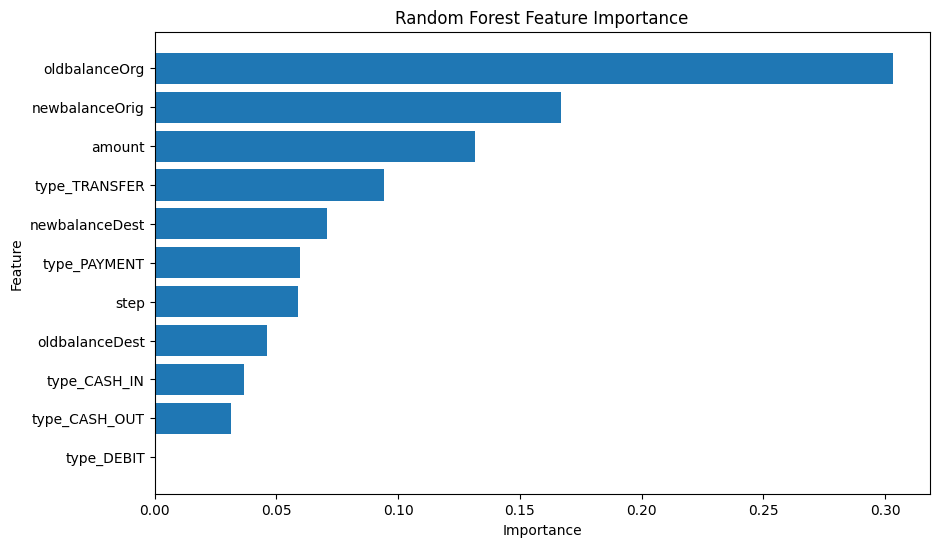

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Random Forest Feature Importance')

plt.gca().invert_yaxis()

plt.show()

In [ ]:
!pip install joblib

In [ ]:
import joblib

joblib.dump(rf_model, 'fraud_detection_model.pkl')

['fraud_detection_model.pkl']

In [ ]:
from google.colab import files

files.download('fraud_detection_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>